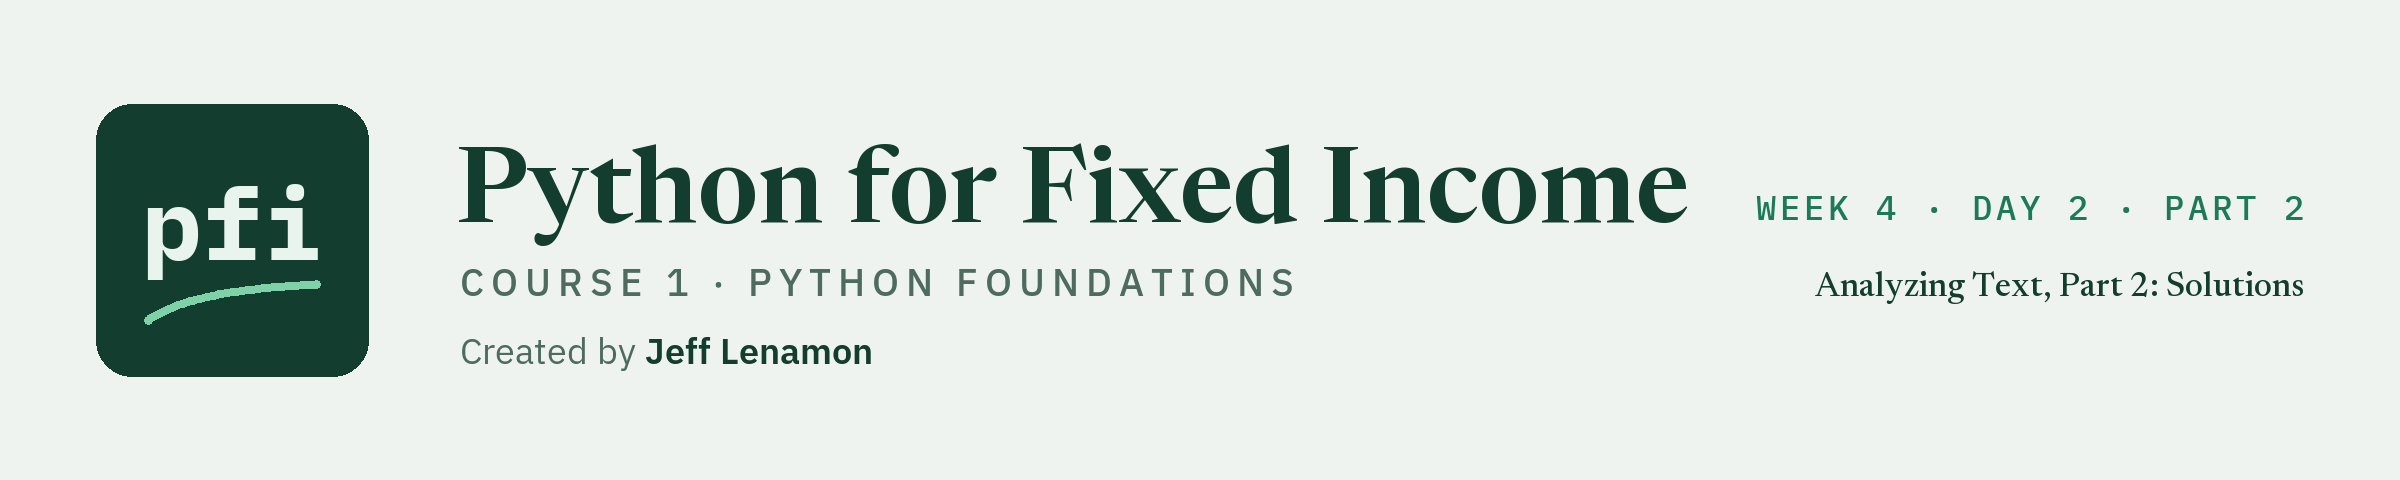

# Analyzing Text, Part 2: Solutions

Week 4, Day 2, Part 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2_part2/17_part2_analyzing_text_solutions.ipynb)

**The data.** The text is real and public, and it is the only data in this notebook.

* Source: Board of Governors of the Federal Reserve System, Federal Open Market Committee statements, federalreserve.gov. Each statement was downloaded from its own press release page, which is linked from the calendar page https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm. Retrieved on 2026-10-03.
* Reuse: the Board's website says, at https://www.federalreserve.gov/disclaimer.htm, "Unless otherwise indicated, information on Board's website is in the public domain and may be copied and distributed without permission. Please cite to the Board as the source of the information."
* The text in the file is exactly as published. The only change made when the file was built was to white space: one space between words, and one line break between paragraphs.

## Before You Start: Install the Libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


## Exercises

Exercise 1 uses a second statement, the one dated 2022-09-21, stored as `other`.

Exercises 2 and 3 use the whole table, and so do the two AI checks, exercises 4 and 5.

Every answer is a count, a figure, or a piece of text taken from a file.

None is a reading of what a statement means.

Each exercise below is answered in full, and the check cell after it prints the result.

Run the next cell first.

It imports the libraries, defines `check`, a small function that marks your answers, defines `clean()` as in the lesson, loads nltk's stopword list as `stop_words`, and loads a fresh `statements`.

It prints the shape of the table, (46, 3), the number of stopwords, 198, and the type of `other`.

In [2]:
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


def clean(text):
    # the four cleaning steps of the lesson: lower case, letters only, single spaces, tokens
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.split(' ')


# nltk's English stopword list, downloaded once
ready = nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

stop_words = stopwords.words('english')

# a fresh copy of the statements. In Colab the file is read from GitHub.
if os.path.exists('../../../data/fomc_statements.csv'):
    data_file = '../../../data/fomc_statements.csv'
else:
    data_file = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/fomc_statements.csv'

statements = pd.read_csv(data_file)

# the statement the first exercise uses
other = statements.loc[statements['date'] == '2022-09-21', 'text'].iloc[0]

print(statements.shape)
print(len(stop_words))
print(type(other))

(46, 3)
198
<class 'str'>


### Exercise 1

Q. Clean `other` with `clean()`. How many tokens are there? Remove nltk's stopwords. How many are left, and which token is the most common? Store the answers in **ex1_tokens**, **ex1_kept**, and **ex1_top**.

In [3]:
tokens = clean(other)
ex1_tokens = len(tokens)

# keep the tokens that are not stopwords
kept = [token for token in tokens if token not in stop_words]
ex1_kept = len(kept)

# most_common(1) is a list holding one (token, count) pair
counts = Counter(kept)
ex1_top = counts.most_common(1)[0][0]

print('Tokens:', ex1_tokens)
print('After stopword removal:', ex1_kept)
print(counts.most_common(4))
print('Most common:', ex1_top)

Tokens: 315
After stopword removal: 201
[('committee', 9), ('inflation', 7), ('rate', 3), ('economic', 3)]
Most common: committee


315 tokens, and 201 after stopword removal.

The most common token in the statement dated 2022-09-21 is `committee`, 9 times, then `inflation` 7, `rate` 3, and `economic` 3.

In [4]:
check('Exercise 1 tokens', ex1_tokens, 315)
check('Exercise 1 kept', ex1_kept, 201)
check('Exercise 1 most common', ex1_top, 'committee')

Exercise 1 tokens: correct
Exercise 1 kept: correct
Exercise 1 most common: correct


### Exercise 2

Q. On the whole table: add a `words` column with the word count of each statement by `split()`, and a `year` column. Which year has the highest mean word count, and what is that mean? Store them in **ex2_year** and **ex2_mean**, the mean rounded to 1 decimal place. Then count the statements that contain the whole word `uncertain`, capitals ignored, and store the count in **ex2_uncertain**. Draw the mean word count by year as a bar chart.

year
2021    505.5
2022    361.1
2023    342.5
2024    348.5
2025    337.5
2026    228.0
Name: words, dtype: float64
Highest: 2021 505.5
Statements with the word uncertain: 19
Statements with the letters uncertain: 32


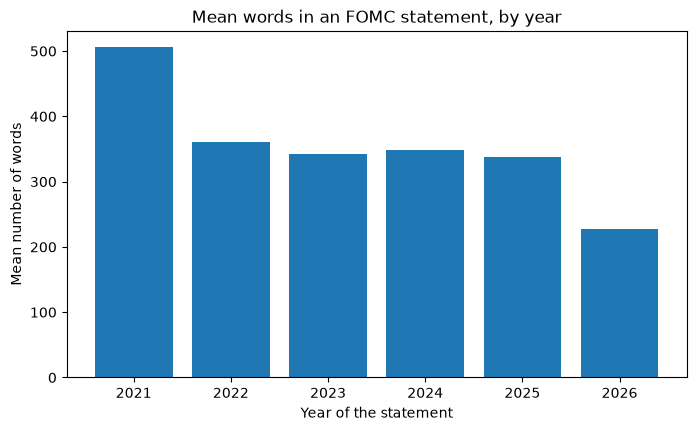

In [5]:
statements['words'] = statements['text'].str.split().str.len()
statements['year'] = pd.to_datetime(statements['date'], format='%Y-%m-%d').dt.year

# the mean word count of each year
by_year = statements.groupby('year')['words'].mean().round(1)
print(by_year)

# idxmax() gives the label of the highest value. int() turns it into a plain whole number.
ex2_year = int(by_year.idxmax())
ex2_mean = float(by_year.max())
print('Highest:', ex2_year, ex2_mean)

# \b on each side, so that uncertainty is not counted
ex2_uncertain = int(statements['text'].str.lower().str.contains(r'\buncertain\b').sum())
print('Statements with the word uncertain:', ex2_uncertain)
print('Statements with the letters uncertain:', statements['text'].str.lower().str.contains('uncertain').sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(by_year.index, by_year.values)
ax.set_title('Mean words in an FOMC statement, by year')
ax.set_xlabel('Year of the statement')
ax.set_ylabel('Mean number of words')
plt.show()

2021 has the highest mean, 505.5 words.

The other years are between 228.0 and 361.1.

19 statements contain the whole word `uncertain`.

Without `\b` the count is 32, because the pattern then also matches `uncertainty`.

These are counts of words and of statements.

They say nothing about what any statement means.

In [6]:
check('Exercise 2 year', ex2_year, 2021)
check('Exercise 2 mean words', ex2_mean, 505.5)
check('Exercise 2 uncertain', ex2_uncertain, 19)

Exercise 2 year: correct
Exercise 2 mean words: correct
Exercise 2 uncertain: correct


### Exercise 3

Q. Build the document-term table for every different token. For each statement, clean the text with `clean()` and keep the tokens that are not in `stop_words`. Make a `Counter` of each statement's kept tokens and a table with one row for each statement and one column for each token. How many different tokens are there, and what share of all the kept tokens, in percent rounded to 1 decimal place, do the 20 most common cover? Store them in **ex3_vocabulary** and **ex3_share**.

In [7]:
# the kept tokens of each statement, then a Counter of each
kept = statements['text'].apply(clean).apply(lambda tokens: [token for token in tokens if token not in stop_words])
counters = kept.apply(Counter)

# one column for each different token, 0 where a statement lacks it
table = pd.DataFrame(list(counters)).fillna(0).astype(int)

ex3_vocabulary = table.shape[1]

# the 20 tokens with the highest totals, and the share of all kept tokens they make up
totals = table.sum()
ex3_share = round(totals.nlargest(20).sum() / totals.sum() * 100, 1)

print('Statements and different tokens:', table.shape)
print('The 20 most common tokens cover', totals.nlargest(20).sum(), 'of', totals.sum(), 'kept tokens:', ex3_share, 'percent')

Statements and different tokens: (46, 507)
The 20 most common tokens cover 3066 of 10204 kept tokens: 30.0 percent


507 different tokens in 46 statements.

The 20 most common cover 3,066 of the 10,204 kept tokens, which is 30.0 percent.

The 10 most common cover 20.4 percent and the 50 most common 48.0 percent.

70 of the 507 tokens appear once in the whole file.

A short vocabulary keeps the common words and drops those rare ones, which is the idea behind a library setting that limits the vocabulary to the most common words.

**Excel side by side.** The table is a pivot table with the statement in Rows, the token in Columns, and the count in Values, built from a sheet with one row for each token of each statement.

In [8]:
check('Exercise 3 different tokens', ex3_vocabulary, 507)
check('Exercise 3 share covered', ex3_share, 30.0)

Exercise 3 different tokens: correct
Exercise 3 share covered: correct


### Exercise 4: AI check

You ask an AI assistant to pull the range out of every statement and say how many statements have one.

It gives you the code below.

It was written for this course in the style of an AI assistant's answer.

It runs without an error, and it contains one bug.

Q. Read the code before you run it. How many statements should have a range? The lesson worked it out. Then run the code. Does the answer agree with you?

The lesson found a range in every one of the 46 statements.

The original code reported 6, with no error and no warning.

The bug was the pattern `\d+ to \d+ percent`.

It allows only digits on each side of `to`, so it cannot match a figure with a slash or a hyphen in it, such as `5-1/4 to 5-1/2 percent`.

Most statements write the range that way, and the pattern silently skipped them.

The 6 matches it did return are worse than a miss.

They read `4 to 1 percent`, `4 to 4 percent`, and `4 to 5 percent`.

None of those is a range in a statement.

Each is the tail of one figure and the start of the next: `3/4 to 1 percent`, `3-3/4 to 4 percent`, `4-3/4 to 5 percent`.

The fix is the class from the lesson, with the slash and both hyphens: `[\d/\u2011-]+`.

The check was the count: 46 statements, so 46 expected.

In [9]:
# a figure may hold digits, slashes, and either kind of hyphen
pattern = r'[\d/\u2011-]+ to [\d/\u2011-]+ percent'

found = statements['text'].str.findall(pattern)

# the number of statements with at least one match
ex4_statements = int((found.str.len() > 0).sum())

# the range in the first statement
ex4_first = found.iloc[0][0]

print('Statements with a range:', ex4_statements)
print('Range in the statement dated', statements['date'].iloc[0] + ':', ex4_first)

Statements with a range: 46
Range in the statement dated 2021-01-27: 0 to 1/4 percent


In [10]:
check('Exercise 4 statements with a range', ex4_statements, 46)
check('Exercise 4 first range', ex4_first, '0 to 1/4 percent')

Exercise 4 statements with a range: correct
Exercise 4 first range: correct


### Exercise 5: AI check

You ask an AI assistant: how many times does the word rate appear in the statements?

It gives you the code below.

It was written for this course in the style of an AI assistant's answer.

It runs without an error, and it contains one bug.

Q. Read the code before you run it. The lesson has two numbers for this, one from each part: the word rate appears 3 times in the statement dated 2023-11-01, and 163 times across the 46 statements. What will this code print?

It printed 4 and 188.

The lesson's numbers are 3 and 163.

No error, no warning, and both answers look reasonable.

The only way to catch it is to hold a number worked out another way.

The bug is `count('rate')`.

It counts the four letters wherever they fall, inside longer words too.

Q. Which words did it count?

In [11]:
# every word that contains the letters rate, across all statements
containing = Counter()
for text in statements['text']:
    containing.update(re.findall(r'\w*rate\w*', text))
print(containing)

# the fix: ask for the whole word
one = statements.loc[statements['date'] == '2023-11-01', 'text'].iloc[0]
ex5_one = len(re.findall(r'\brate\b', one))
ex5_total = int(statements['text'].str.count(r'\brate\b').sum())

print('Whole word, one statement:', ex5_one)
print('Whole word, all statements:', ex5_total)

Counter({'rate': 163, 'moderately': 14, 'moderated': 7, 'moderate': 3, 'concentrated': 1})
Whole word, one statement: 3
Whole word, all statements: 163


The 188 is made of 163 for `rate` and 25 for other words that contain it: `moderately` 14 times, `moderated` 7, `moderate` 3, and `concentrated` 1.

With `\b` on each side the code returns 3 and 163, the lesson's numbers.

The code was not careless in an obvious way.

`count()` is the natural tool, and on many words it gives the right answer.

The check is always the same: one number worked out by hand, on one document small enough to read.

In [12]:
check('Exercise 5 one statement', ex5_one, 3)
check('Exercise 5 all statements', ex5_total, 163)

Exercise 5 one statement: correct
Exercise 5 all statements: correct
